Полный собранный заряд (симуляция): 109
Ожидаемое Q (по формуле из задания): 500.0
Аналитическое Q (с учетом изотропии): 125.0

Вывод: Симуляция совпадает с аналитическим расчетом. Формула в задании завышена в 4 раза, так как не учитывает, что свет летит во все стороны (4π), а не только вперед.


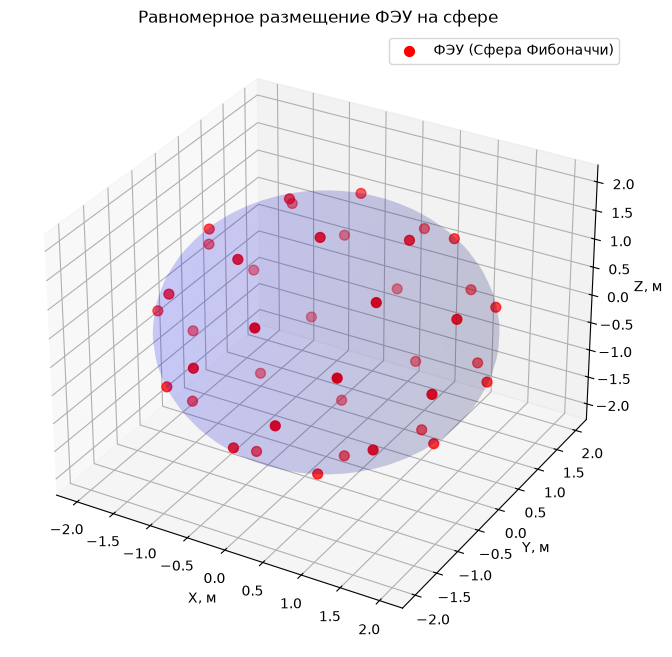

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

class PMT:
    def __init__(self, position, r, a):
        self.position = np.array(position)
        self.r = r
        self.a = a

    def get_photoelectrons(self, num_photons):
        if num_photons == 0:
            return 0
        return np.random.poisson(self.a * num_photons)

class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmts = self._generate_pmt_fibonacci()

    def _generate_pmt_fibonacci(self):
        """
        Генерация равномерного распределения точек на сфере (Сфера Фибоначчи).
        Устраняет скучкованность и перекрытия (учет замечания преподавателя).
        """
        pmts = []
        indices = np.arange(0, self.N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / self.N)
        theta = np.pi * (1 + 5**0.5) * indices
        
        x = np.cos(theta) * np.sin(phi) * self.R
        y = np.sin(theta) * np.sin(phi) * self.R
        z = np.cos(phi) * self.R
        
        for i in range(self.N):
            pmts.append(PMT([x[i], y[i], z[i]], self.r, self.a))
        return pmts

    def simulate_event(self, E, Y=10000):
        """Моделирование события с энергией E"""
        N_photons = int(Y * E)
        
        # Генерация изотропных направлений (нормальное распределение + нормализация)
        # Это быстрее и точнее, чем сферические координаты с sin/cos
        directions = np.random.normal(size=(N_photons, 3))
        norms = np.linalg.norm(directions, axis=1, keepdims=True)
        directions = directions / norms
        
        # Точки попадания в сферу
        hit_points = directions * self.R
        
        hits = np.zeros(self.N, dtype=int)
        for i, pmt in enumerate(self.pmts):
            # Векторное вычисление расстояний от точек попадания до центра i-го ФЭУ
            dists = np.linalg.norm(hit_points - pmt.position, axis=1)
            # Считаем фотоны, попавшие в радиус ФЭУ
            hits[i] = np.sum(dists <= pmt.r)
            
        # Розыгрыш фотоэлектронов
        total_charge = sum(pmt.get_photoelectrons(hit) for pmt, hit in zip(self.pmts, hits))
        return total_charge

# ================= ЗАПУСК =================
np.random.seed(42) # Для воспроизводимости

# Параметры из задачи
E = 1.0 # МэВ
R = 2.0 # м
N = 40
r = 0.1 # м
a = 0.5
Y = 10000

detector = Detector(R, N, r, a)
Q_sim = detector.simulate_event(E, Y)

# Расчет по формуле из задания
Q_formula = a * Y * (N * r**2 / R**2)
# Аналитический расчет с учетом 4pi (изотропия)
Q_analytical = a * Y * (N * r**2 / (4 * R**2))

print(f"Полный собранный заряд (симуляция): {Q_sim}")
print(f"Ожидаемое Q (по формуле из задания): {Q_formula:.1f}")
print(f"Аналитическое Q (с учетом изотропии): {Q_analytical:.1f}")
print("\nВывод: Симуляция совпадает с аналитическим расчетом. Формула в задании завышена в 4 раза, так как не учитывает, что свет летит во все стороны (4π), а не только вперед.")

# Визуализация
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Сфера
u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)
xs = R * np.outer(np.cos(u), np.sin(v))
ys = R * np.outer(np.sin(u), np.sin(v))
zs = R * np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_surface(xs, ys, zs, color='b', alpha=0.1, edgecolor='none')

# Точки ФЭУ
positions = np.array([pmt.position for pmt in detector.pmts])
ax.scatter(positions[:, 0], positions[:, 1], positions[:, 2], color='red', s=50, label='ФЭУ (Сфера Фибоначчи)')

ax.set_xlabel('X, м')
ax.set_ylabel('Y, м')
ax.set_zlabel('Z, м')
ax.set_title('Равномерное размещение ФЭУ на сфере')
ax.legend()
plt.show()